# 03 - Cycles table

One row per cell and cycle, from the `summary` field: discharge and charge capacity, internal resistance, temperature and charge time.

Opening the .mat files is slow, so I save this once as Parquet and load that from now on. Like `cells.csv`, it lives in `data/` and isn't committed.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd
from src.load import open_batch, n_cells, get_summary

In [2]:
# summary field name -> column name
COLUMNS = {
    "cycle": "cycle",
    "QDischarge": "q_discharge",
    "QCharge": "q_charge",
    "IR": "ir",
    "Tmax": "t_max",
    "Tavg": "t_avg",
    "Tmin": "t_min",
    "chargetime": "charge_time",
}

parts = []
for batch in [1, 2, 3]:
    f = open_batch(batch, root="../")
    for i in range(n_cells(f)):
        s = get_summary(f, i)
        df = pd.DataFrame({new: s[old] for old, new in COLUMNS.items()})
        df.insert(0, "cell_id", f"b{batch}c{i}")
        parts.append(df)
    f.close()

cycles = pd.concat(parts, ignore_index=True)
cycles["cycle"] = cycles["cycle"].astype(int)
print(cycles.shape)
cycles.head()

(114738, 9)


,cell_id,cycle,q_discharge,q_charge,ir,t_max,t_avg,t_min,charge_time
0,b1c0,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,b1c0,2,1.070689,1.071042,0.016742,35.652016,31.875011,29.566130,13.341250
2,b1c0,3,1.071900,1.071674,0.016724,35.692978,31.931490,29.604385,13.425777
3,b1c0,4,1.072510,1.072304,0.016681,35.680588,31.932603,29.744202,13.425167
4,b1c0,5,1.073174,1.072970,0.016662,35.728691,31.959322,29.644709,13.341442


## Quick checks

In [3]:
cycles.describe().round(4).T

,count,mean,std,min,25%,50%,75%,max
cycle,114738.0,486.2214,372.1202,1.0,206.0000,414.5000,682.0000,2237.0000
q_discharge,114738.0,1.0316,0.0548,0.0,1.0148,1.0485,1.0674,2.8841
q_charge,114738.0,1.0317,0.0553,0.0,1.0149,1.0483,1.0671,2.9659
ir,114738.0,0.0165,0.0013,0.0,0.0155,0.0165,0.0173,0.0244
t_max,114738.0,37.9215,2.6068,0.0,36.3528,38.1583,39.7636,44.6629
t_avg,114738.0,34.2369,2.0586,0.0,32.9518,34.0503,35.6026,41.4403
t_min,114738.0,31.3371,1.6605,0.0,30.1476,31.1877,32.4805,36.6912
charge_time,114738.0,11.1458,6.1628,0.0,10.0644,10.6380,11.2918,1290.3708


In [4]:
# cycle numbers should run 1, 2, 3, ... without gaps in every cell
gaps = cycles.groupby("cell_id")["cycle"].apply(lambda x: (x.diff().dropna() != 1).sum())
print("cells with gaps in cycle numbers:", (gaps > 0).sum())
print("missing values:", cycles.isna().sum().sum())

cells with gaps in cycle numbers: 0
missing values: 0


In [5]:
# zeros in places where a real measurement can't be zero
for col in ["q_discharge", "ir", "charge_time", "t_max"]:
    zero = cycles[cycles[col] == 0]
    print(f"{col}: {len(zero)} zero rows in {zero['cell_id'].nunique()} cells, cycles {sorted(zero['cycle'].unique())[:10]}")

q_discharge: 46 zero rows in 46 cells, cycles [np.int64(1)]
ir: 68 zero rows in 49 cells, cycles [np.int64(1), np.int64(12), np.int64(13), np.int64(311), np.int64(313), np.int64(331), np.int64(848), np.int64(850), np.int64(853), np.int64(873)]
charge_time: 46 zero rows in 46 cells, cycles [np.int64(1)]
t_max: 46 zero rows in 46 cells, cycles [np.int64(1)]


In [6]:
# zero resistance after the first cycle is a measurement dropout, not a real value
z = cycles[(cycles["ir"] == 0) & (cycles["cycle"] > 1)]
print(len(z), "rows in", z["cell_id"].nunique(), "cells:", z["cell_id"].unique().tolist())

22 rows in 19 cells: ['b1c0', 'b1c1', 'b1c2', 'b1c3', 'b1c4', 'b1c5', 'b1c6', 'b1c7', 'b1c9', 'b1c10', 'b1c11', 'b1c16', 'b1c20', 'b1c21', 'b1c23', 'b1c40', 'b2c7', 'b2c8', 'b2c9']


## Outliers

Charge time is in minutes. Fast charging should take roughly 10 to 15 minutes, so anything far outside that is worth a look.

In [7]:
print("charge time quantiles:")
print(cycles["charge_time"].quantile([0.001, 0.01, 0.5, 0.99, 0.999]).round(2))

long = cycles[cycles["charge_time"] > 60]
print(len(long), "cycles with charge time over 60 min, in cells", sorted(long["cell_id"].unique()))

charge time quantiles:
0.001     8.99
0.010     9.96
0.500    10.64
0.990    20.00
0.999    23.73
Name: charge_time, dtype: float64
14 cycles with charge time over 60 min, in cells ['b1c14', 'b1c15', 'b1c24', 'b1c3', 'b1c41', 'b1c5', 'b2c12', 'b2c2', 'b2c23', 'b2c39', 'b2c41', 'b2c44', 'b2c5', 'b2c9']


In [8]:
print("discharge capacity above 1.2 Ah (more than a new cell can hold):")
high = cycles[cycles["q_discharge"] > 1.2]
print(len(high), "rows in cells", sorted(high["cell_id"].unique()))
high.sort_values("q_discharge", ascending=False).head(10)

discharge capacity above 1.2 Ah (more than a new cell can hold):
4 rows in cells ['b1c0', 'b1c18', 'b2c12', 'b2c44']


,cell_id,cycle,q_discharge,q_charge,ir,t_max,t_avg,t_min,charge_time
17344,b1c18,40,2.884085,2.965895,0.019886,35.454494,30.761674,29.988739,9.958420
61791,b2c44,248,1.544718,1.430044,0.020722,36.084797,31.807028,30.065310,492.161670
11,b1c0,12,1.539054,1.546792,0.018950,35.237232,30.282579,29.012251,13.341273
45711,b2c12,253,1.489119,1.381343,0.019708,36.286880,31.947664,29.880760,491.139770


## A few cells over time

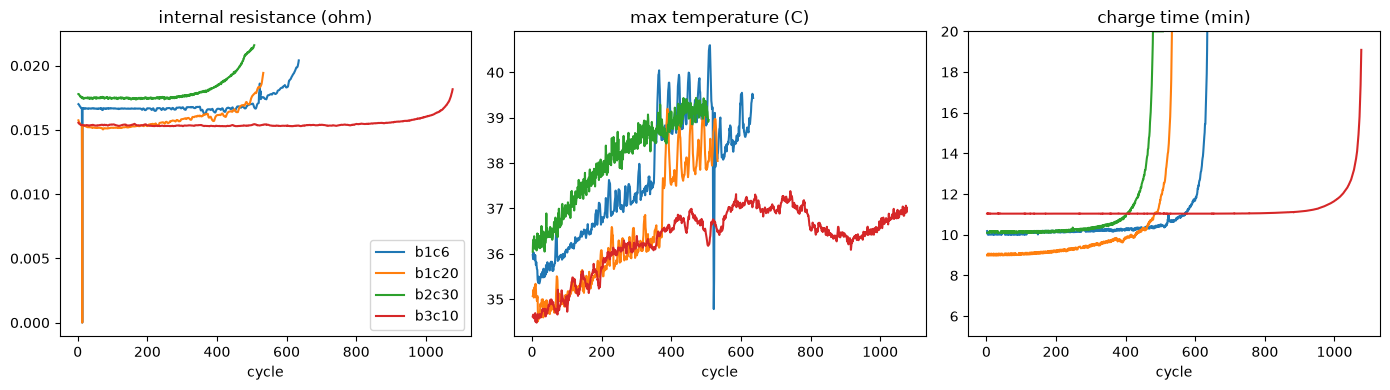

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for cell in ["b1c6", "b1c20", "b2c30", "b3c10"]:
    d = cycles[cycles["cell_id"] == cell]
    d = d[d["cycle"] > 1]
    axes[0].plot(d["cycle"], d["ir"], label=cell)
    axes[1].plot(d["cycle"], d["t_max"], label=cell)
    axes[2].plot(d["cycle"], d["charge_time"], label=cell)
axes[0].set_title("internal resistance (ohm)")
axes[1].set_title("max temperature (C)")
axes[2].set_title("charge time (min)")
axes[2].set_ylim(5, 20)
for ax in axes:
    ax.set_xlabel("cycle")
axes[0].legend()
plt.tight_layout()
plt.savefig("../reports/figures/ir_temp_chargetime.png", dpi=120)
plt.show()

## Save

In [10]:
cycles.to_parquet("../data/cycles.parquet", index=False)
print("saved", len(cycles), "rows")

saved 114738 rows


## Notes

- 114,738 rows over 140 cells. Cycle numbers run 1, 2, 3, ... with no gaps, and nothing is missing (no NaN).
- In batch 1 the first cycle is all zeros in every cell, same as in notebook 01. Features should start at cycle 2.
- Internal resistance drops to 0 in 22 rows after the first cycle, spread over 19 cells: 16 in batch 1, plus b2c7 to b2c9, which are continued batch 1 cells. That's the meter dropping out, so I'll treat 0 as missing.
- 14 cycles have a charge time over 60 minutes (up to about 1,290). Probably the test paused in the middle of a charge.
- 4 rows show a discharge capacity above 1.2 Ah, up to 2.88 Ah, which is impossible for a 1.1 Ah cell. Two of them (b2c12, b2c44) happen on the same cycle as a charge time of about 490 minutes, so they look like the same kind of pause.
- Near the end of life, resistance goes up and charge time shoots up. The cell can't take the charge fast anymore, so the charger spends longer at constant voltage. Temperature is noisier and also creeps up.
- b3c10 (the batch 3 cell in the plot) keeps an almost constant charge time of about 11 minutes and stays cooler than the three cells from batches 1 and 2. One cell isn't enough to say this about the whole batch, so notebook 05 compares the batches properly.
- None of these glitches are fixed in the saved file. The cleaning rules go into step 1.5, where I decide what to drop or smooth, and why.